# Where the risk of the multi-factor strategy comes from

The multi-factor strategy of the companion repository, [brazil-equity-factors](https://github.com/pedroandion/brazil-equity-factors) (notebook `05_multi_factor_strategy`), and its three sleeves:

| Strategy | Stocks | Rule |
|---|---|---|
| Magic Formula | 10 | Return on capital, earnings yield, net debt / EBIT, low volatility and momentum, ranked together; financials and utilities excluded |
| LowVol Momentum | 10 | The least volatile stocks among the top 20% by momentum |
| Quality | 10 | Profitability and value, without the 20% weakest in leverage or growth |
| Combination | Up to 30 | The three sleeves together; a stock picked by more than one gets a larger weight |

All four are long-only, equally weighted and rebalanced on the first business day of each month, before transaction costs. Quality holds no stocks until February 2011, when its growth signals have two years of history, so the sample starts in January 2012, the first full year with all three sleeves. This notebook regresses their returns in excess of the SELIC rate on the seven local factors, original and orthogonal, and splits their variance among the factors, as Tables 4 to 6 of the paper do for the US portfolios.

In [1]:
# Library imports

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter
from pathlib import Path

from orthofactors.data import (load_brazil_factors, load_brazil_strategies, to_monthly, BRAZIL_FACTORS,
                               BRAZIL_STRATEGIES, MONTHLY_SAMPLE)
from orthofactors.orthogonalization import orthogonalize_swl_correlation
from orthofactors.decomposition import run_ols, decompose, variance_levels, gs_order_range
from orthofactors.plotting import set_style, factor_colors, plot_decomposition_bars

set_style()
Path('results').mkdir(exist_ok = True)
colors = factor_colors(BRAZIL_FACTORS)

## Data

Daily returns from 2012-01-02 to 2026-07-23, in excess of the SELIC rate, the same risk-free rate as the market factor. The monthly returns compound the daily excess returns, as the companion does, from January 2012 to June 2026 (174 months). The t-statistics use Newey-West errors, with 4 lags in monthly data and 5 in daily data.

In [2]:
factors_daily = load_brazil_factors()[BRAZIL_FACTORS]
strategies_daily = load_brazil_strategies()
factors = to_monthly(factors_daily).loc[MONTHLY_SAMPLE]
strategies = to_monthly(strategies_daily).loc[MONTHLY_SAMPLE]

pd.DataFrame({'Mean excess return': strategies.mean() * 12, 'Volatility': strategies.std() * np.sqrt(12),
              'Months': strategies.count()}).style.format({'Mean excess return': '{:.2%}', 'Volatility': '{:.2%}'})

,Mean excess return,Volatility,Months
Combination,6.01%,19.11%,174
Magic Formula,6.61%,19.24%,174
LowVol Momentum,6.13%,18.94%,174
Quality,5.16%,24.06%,174


## Betas and alpha

In [3]:
# Regressions on the original factors and on the factors orthogonalized on the same months
original = {s: run_ols(strategies[s], factors, hac_lags = 4) for s in BRAZIL_STRATEGIES}
orthogonal = {s: decompose(strategies[s], factors, hac_lags = 4) for s in BRAZIL_STRATEGIES}

betas = pd.DataFrame({s: pd.concat([original[s].params[BRAZIL_FACTORS], orthogonal[s][0].params[BRAZIL_FACTORS]],
                                   keys = ['β', 'β⊥']) for s in BRAZIL_STRATEGIES}).T
tstats = pd.DataFrame({s: pd.concat([original[s].tvalues[BRAZIL_FACTORS], orthogonal[s][0].tvalues[BRAZIL_FACTORS]],
                                    keys = ['β', 'β⊥']) for s in BRAZIL_STRATEGIES}).T
betas.round(2)

β                                         β⊥              \
                Mkt_RF   SMB   HML   RMW   CMA   WML   BAB Mkt_RF   SMB   HML   
Combination       0.84  0.37  0.03  0.21  0.02  0.18  0.30   0.77  0.41  0.10   
Magic Formula     0.78  0.42 -0.04  0.18 -0.01  0.18  0.38   0.71  0.42  0.02   
LowVol Momentum   0.82  0.31  0.08  0.15  0.07  0.40  0.32   0.73  0.31  0.07   
Quality           0.90  0.36  0.05  0.31 -0.01 -0.03  0.21   0.88  0.50  0.19   

                                         
                  RMW   CMA   WML   BAB  
Combination      0.18 -0.06  0.02  0.07  
Magic Formula    0.19 -0.11  0.05  0.16  
LowVol Momentum  0.12 -0.01  0.21  0.13  
Quality          0.23 -0.07 -0.19 -0.06

In [4]:
tstats.round(2)

β                                         β⊥         \
                Mkt_RF   SMB   HML   RMW   CMA   WML   BAB Mkt_RF    SMB   
Combination      26.10  7.15  0.41  3.87  0.33  3.54  6.70  27.78  10.11   
Magic Formula    17.05  6.54 -0.38  2.57 -0.20  2.35  6.08  17.10   8.68   
LowVol Momentum  24.28  5.01  1.02  2.28  1.11  7.72  5.88  27.18   6.77   
Quality          18.00  4.38  0.43  3.97 -0.06 -0.38  2.69  20.13   7.74   

                                               
                  HML   RMW   CMA   WML   BAB  
Combination      2.75  4.16 -1.22  0.64  2.42  
Magic Formula    0.47  3.32 -1.82  0.97  3.53  
LowVol Momentum  2.02  2.60 -0.17  5.64  3.50  
Quality          3.03  3.59 -0.84 -2.88 -1.10

In [5]:
# The alpha, its t-statistic and the R² are the same with both sets of factors
pd.DataFrame({s: {'Alpha per month, original': original[s].params['const'], 'Alpha per month, orthogonal': orthogonal[s][0].params['const'],
                  't, original': original[s].tvalues['const'], 't, orthogonal': orthogonal[s][0].tvalues['const'],
                  'R², original': original[s].rsquared, 'R², orthogonal': orthogonal[s][0].rsquared}
              for s in BRAZIL_STRATEGIES}).T.style.format('{:.4f}')

,"Alpha per month, original","Alpha per month, orthogonal","t, original","t, orthogonal","R², original","R², orthogonal"
Combination,0.0027,0.0027,1.6189,1.6189,0.8635,0.8635
Magic Formula,0.0033,0.0033,1.5885,1.5885,0.7538,0.7538
LowVol Momentum,0.0001,0.0001,0.0321,0.0321,0.7902,0.7902
Quality,0.0044,0.0044,1.4842,1.4842,0.7565,0.7565


With the beta-neutral BAB, the strategies lean to low-beta stocks in both versions: the BAB beta of the Combination is +0.30 on the original factors and +0.07 on the orthogonal ones, both significant. The orthogonal betas differ most for momentum, because the transformation undoes the strong negative correlation between value and momentum: the momentum beta of the Combination falls from 0.18 to 0.02, and that of Quality from −0.03 to −0.19. All four strategies have positive and significant betas on the market, SMB and RMW in both versions.

The alpha is the same with both sets of factors, as Appendix A of the paper shows, and so are its t-statistic and the R². No alpha is significant at 5% in this sample: the Combination earns 0.27% a month beyond the seven factors, with a t-statistic of 1.6, the Magic Formula 0.33% (1.6), Quality 0.44% (1.5) and LowVol Momentum 0.01%. These are in-sample results before costs: as the companion notes, the strategy and its parameter tests use the same sample.

## The systematic variance, factor by factor

In [6]:
# Monthly variances in percent squared: the naive sum of (β_k σ_k)², the systematic variance and its exact split
levels = {s: variance_levels(strategies[s], factors) * 1e4 for s in BRAZIL_STRATEGIES}
pd.DataFrame({s: {'Naive sum': t.loc['sum', 'original'], 'Systematic variance': t.loc['systematic', 'original'],
                  'Orthogonal sum': t.loc['sum', 'orthogonal'], 'Idiosyncratic variance': t.loc['idiosyncratic', 'original'],
                  'Total variance': t.loc['total', 'original']} for s, t in levels.items()}).T.round(2)

,Naive sum,Systematic variance,Orthogonal sum,Idiosyncratic variance,Total variance
Combination,32.21,26.27,26.27,4.15,30.42
Magic Formula,30.79,23.25,23.25,7.59,30.84
LowVol Momentum,34.58,23.62,23.62,6.27,29.89
Quality,35.12,36.49,36.49,11.75,48.24


In [7]:
# Factor by factor for the Combination
levels['Combination'].round(2)

,original,orthogonal
Mkt_RF,25.65,21.90
SMB,2.81,3.50
HML,0.02,0.23
RMW,0.63,0.46
CMA,0.00,0.04
WML,1.01,0.02
BAB,2.09,0.13
sum,32.21,26.27
systematic,26.27,26.27
idiosyncratic,4.15,4.15


Without the orthogonalization, adding up the terms of each factor overstates the systematic risk: by 23% for the Combination (32.2 against 26.3), 32% for the Magic Formula and 46% for LowVol Momentum, while for Quality it is about right, 4% too low. In the US data of the paper the naive sum was usually too small, because the main factors were positively correlated. Here the strategies have positive betas on factors that move against each other, such as the market and BAB (−0.45), size and BAB (−0.52) or size and momentum (−0.54), so the cross terms are negative and the naive sum counts risk that cancels out. With the orthogonal factors the terms add up exactly.

## Decomposed $R^2$

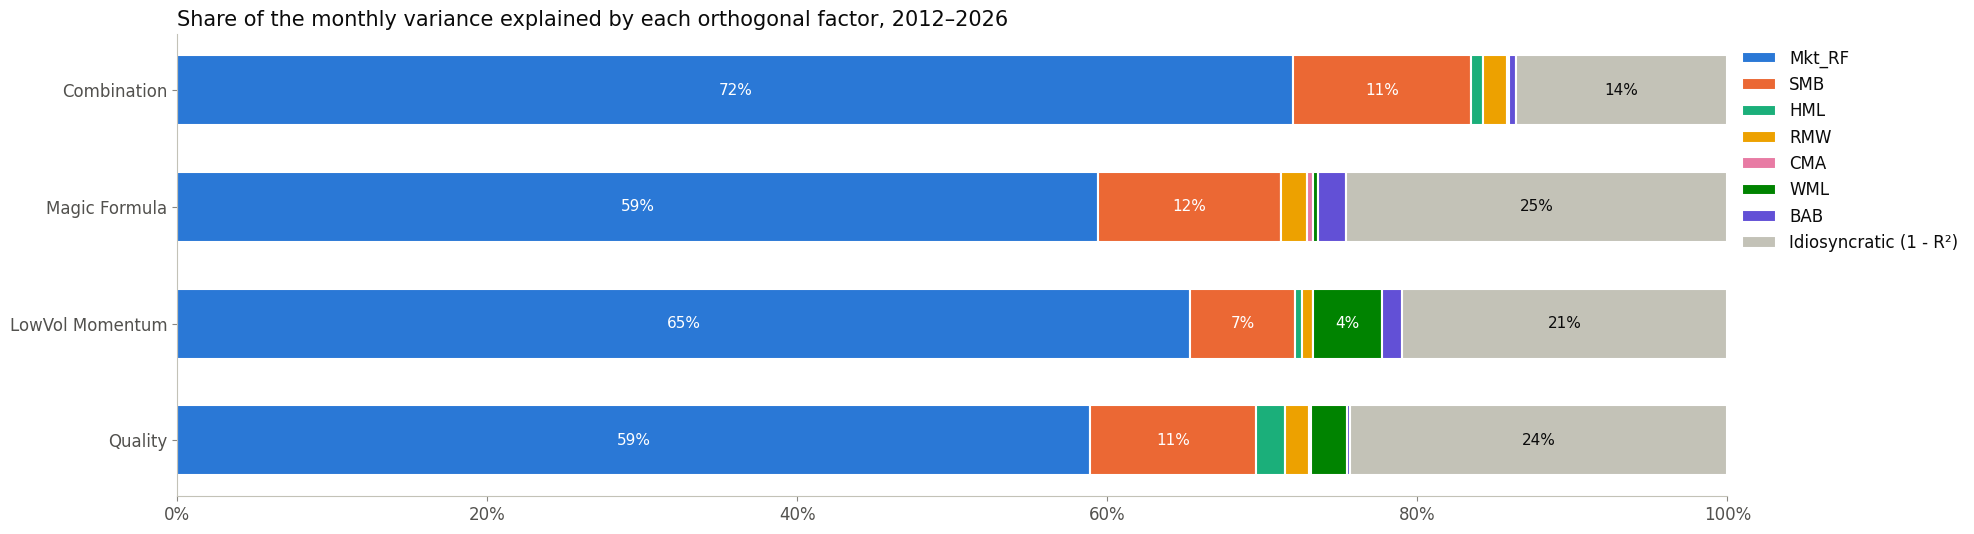

,Mkt_RF,SMB,HML,RMW,CMA,WML,BAB,idiosyncratic
Combination,71.98%,11.49%,0.76%,1.52%,0.14%,0.05%,0.41%,13.65%
Magic Formula,59.37%,11.82%,0.04%,1.65%,0.41%,0.29%,1.80%,24.62%
LowVol Momentum,65.34%,6.76%,0.45%,0.71%,0.00%,4.47%,1.27%,20.98%
Quality,58.88%,10.68%,1.89%,1.56%,0.11%,2.34%,0.19%,24.35%


In [8]:
decomposition = pd.DataFrame({s: pd.concat([orthogonal[s][1], pd.Series({'idiosyncratic': 1 - orthogonal[s][0].rsquared})])
                              for s in BRAZIL_STRATEGIES}).T
assert np.allclose(decomposition.sum(axis = 1), 1)

fig, ax = plt.subplots(figsize = (20, 6))
plot_decomposition_bars(ax, decomposition, BRAZIL_FACTORS, 'Share of the monthly variance explained by each orthogonal factor, 2012–2026')
plt.show()

decomposition.style.format('{:.2%}')

The market explains most of the variance of every strategy, from 59% (Quality and the Magic Formula) to 72% (the Combination), and size comes second, with 7% to 12%. The other five factors together explain from 3% (the Combination) to 7% (LowVol Momentum), where momentum is the largest of them (4.5%); BAB explains at most 1.8%. The idiosyncratic share is 14% for the Combination and 21% to 25% for the sleeves, so combining them diversifies away part of what is specific to each.

With the dollar-neutral BAB of the companion, BAB looked like the third source of risk, with up to 12% of the variance of Quality. Most of that was market risk: with the beta-neutral BAB, its share is 0.2% for Quality and 0.4% for the Combination, and the market's share is higher (see the robustness section).

## What Gram-Schmidt would say

Gram-Schmidt also gives uncorrelated factors, but the answer depends on the order: the first factor keeps everything it shares with the others. The chart runs all 5,040 orders of the seven factors and shows the range of each share, with the SW/L share as a dot.

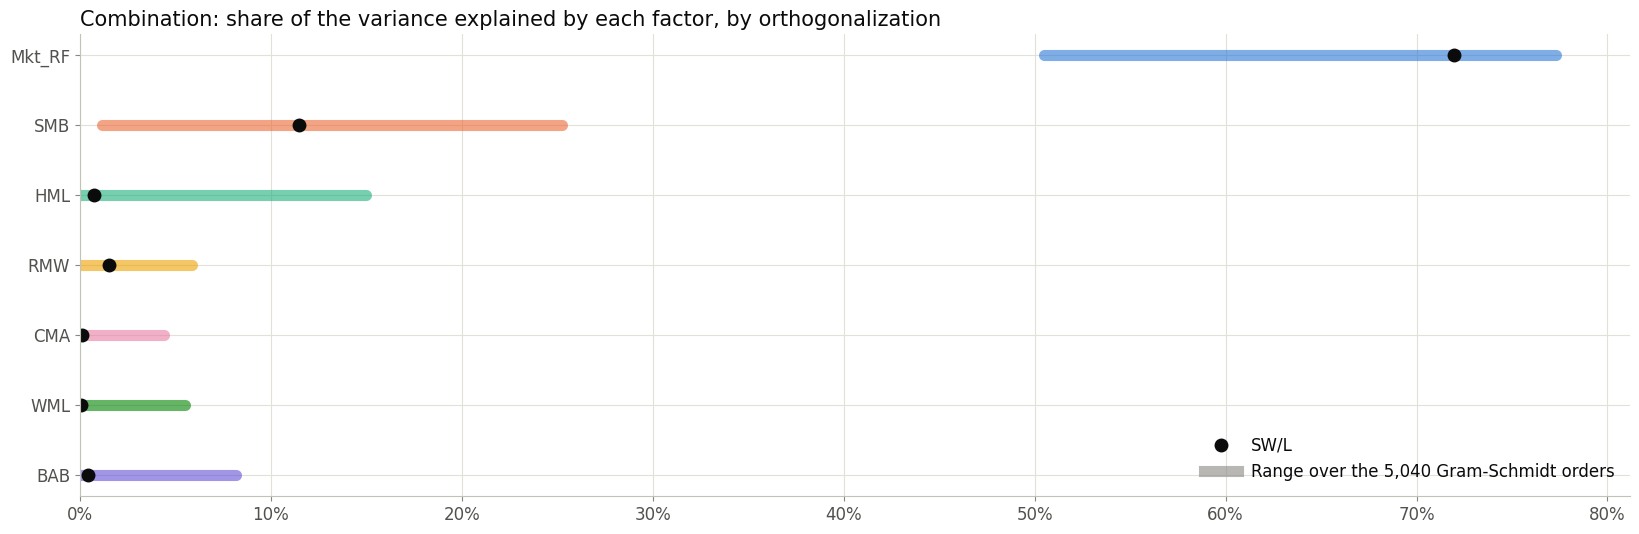

In [9]:
gs_orders = {s: gs_order_range(strategies[s], factors) for s in BRAZIL_STRATEGIES}
gs_range = pd.concat({s: pd.DataFrame({'Lowest': g.min(), 'Highest': g.max(), 'SW/L': decomposition.loc[s, BRAZIL_FACTORS]})
                      for s, g in gs_orders.items()})

fig, ax = plt.subplots(figsize = (20, 6))
combination = gs_range.loc['Combination']
for y, factor in enumerate(BRAZIL_FACTORS):
    ax.plot([combination.loc[factor, 'Lowest'], combination.loc[factor, 'Highest']], [y, y], color = colors[factor],
            linewidth = 8, solid_capstyle = 'round', alpha = 0.6)
    ax.plot(combination.loc[factor, 'SW/L'], y, 'o', color = '#0b0b0b', markersize = 9)
ax.plot([], [], 'o', color = '#0b0b0b', markersize = 9, label = 'SW/L')
ax.plot([], [], color = '#898781', linewidth = 8, alpha = 0.6, label = 'Range over the 5,040 Gram-Schmidt orders')
ax.set_yticks(range(len(BRAZIL_FACTORS)), BRAZIL_FACTORS)
ax.invert_yaxis()
ax.xaxis.set_major_formatter(PercentFormatter(1))
ax.set_xlim(0, None)
ax.set_title('Combination: share of the variance explained by each factor, by orthogonalization')
ax.legend(loc = 'lower right')
plt.show()

gs_range.unstack(0).swaplevel(axis = 1).sort_index(axis = 1, level = 0, sort_remaining = False)[BRAZIL_STRATEGIES].style.format('{:.1%}')

With Gram-Schmidt the answer depends on an arbitrary choice. Depending on the order, the market explains from 50% to 77% of the variance of the Combination, size from 1% to 25% and BAB from 0% to 8%; for Quality, HML goes from 0% to 23%. The SW/L shares sit inside these ranges without favoring any factor, and they do not depend on the order of the columns.

## The model without BAB

The portfolio construction project used six factors, without BAB. The same decomposition with six factors shows what BAB takes from the others.

In [10]:
six = [f for f in BRAZIL_FACTORS if f != 'BAB']
without_bab = {s: decompose(strategies[s], factors[six]) for s in BRAZIL_STRATEGIES}
comparison = pd.concat({'Seven factors': decomposition[['Mkt_RF', 'SMB', 'BAB', 'idiosyncratic']],
                        'Without BAB': pd.DataFrame({s: pd.concat([d, pd.Series({'idiosyncratic': 1 - r.rsquared})])
                                                     for s, (r, d) in without_bab.items()}).T[['Mkt_RF', 'SMB', 'idiosyncratic']]}, axis = 1)
comparison.style.format('{:.2%}', na_rep = '')

Dropping the beta-neutral BAB costs some fit: the idiosyncratic share of the Combination rises from 13.6% to 17.3%, and that of the Magic Formula from 24.6% to 30.1%. With the dollar-neutral BAB the loss was smaller, 16.2% to 17.3% for the Combination. The beta-neutral BAB carries information the other six factors do not, even though its own orthogonal share is small: SW/L splits the variance BAB shares with the other factors among all of them, while dropping BAB loses the part of it that none of the others spans.

## Robustness

The same decomposition with daily returns, with the correlation version of SW/L, which does not change when one factor is rescaled, and with the dollar-neutral BAB of the companion instead of the beta-neutral one.

In [11]:
def decomposition_of(returns, factor_returns, **kwargs):
    rows = {}
    for s in BRAZIL_STRATEGIES:
        result, dr2 = decompose(returns[s], factor_returns, **kwargs)
        rows[s] = pd.concat([dr2, pd.Series({'idiosyncratic': 1 - result.rsquared})])
    return pd.DataFrame(rows).T

robustness = pd.concat({'Monthly': decomposition,
                        'Daily': decomposition_of(strategies_daily, factors_daily),
                        'Monthly, correlation version': decomposition_of(strategies, factors, orthogonalize = orthogonalize_swl_correlation),
                        'Monthly, dollar-neutral BAB': decomposition_of(strategies, to_monthly(load_brazil_factors(bab = 'dollar_neutral')[BRAZIL_FACTORS]).loc[MONTHLY_SAMPLE])})
robustness.style.format('{:.2%}')

The market stays first and size second in daily data and with the correlation version, except for LowVol Momentum in daily data, where momentum (3.8%) edges out size (3.3%). With daily returns the market explains more, 77% of the Combination, and size less, 6%, probably because small caps trade less often and react to news with a lag, which weakens their daily co-movement. The correlation version moves the shares by at most 1.7 points.

With the dollar-neutral BAB of the companion, BAB takes 3.5% to 11.6% of the variance, the market explains 4 to 8 points less, and the idiosyncratic share is 1 to 3 points higher, because that BAB spans less of the strategies.

In [12]:
decomposition.round(4).to_csv('results/strategy_decomposition.csv')
gs_range.round(4).to_csv('results/strategy_gram_schmidt_range.csv')
robustness.round(4).to_csv('results/strategy_decomposition_robustness.csv')